In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, RepeatVector, TimeDistributed, Dense

In [3]:
df = pd.read_csv("AutoEncoder/NASA Turbofan ENgine/NASA TurboFan Engine.csv")

display(df.head())
print(df.shape)

,unit,cycle,setting1,setting2,setting3,sensor1,sensor2,sensor3,sensor4,sensor5,...,sensor14,sensor15,sensor16,sensor17,sensor18,sensor19,sensor20,sensor21,RUL,Fault_Label
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191,0
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190,0
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189,0
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188,0
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187,0


(20631, 28)


In [15]:
X = df.drop(["unit", "cycle", "RUL", "Fault_Label"], axis=1)
y = df["Fault_Label"]

In [16]:
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

x_train = x_train[y_train == 0]

In [17]:
scaler = MinMaxScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [18]:
x_train = x_train.reshape(x_train.shape[0], 1, x_train.shape[1])
x_test = x_test.reshape(x_test.shape[0], 1, x_test.shape[1])

In [19]:
model = Sequential([
    Input(shape=(1, x_train.shape[2])),
    LSTM(32, activation="relu"),
    RepeatVector(1),
    LSTM(32, activation="relu", return_sequences=True),
    TimeDistributed(Dense(x_train.shape[2]))
])

model.compile(optimizer="adam", loss="mse")

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         7,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 1, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 1, 32)          │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 1, 24)          │           792 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,408 (64.09 KB)

 Trainable params: 16,408 (64.09 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
history = model.fit(
    x_train, x_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.0340 - val_loss: 0.0060
Epoch 2/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 0s 827us/step - loss: 0.0045 - val_loss: 0.0037
Epoch 3/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 0s 808us/step - loss: 0.0033 - val_loss: 0.0029
Epoch 4/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 0s 780us/step - loss: 0.0025 - val_loss: 0.0023
Epoch 5/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 0s 787us/step - loss: 0.0019 - val_loss: 0.0017
Epoch 6/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 0s 784us/step - loss: 0.0014 - val_loss: 0.0012
Epoch 7/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 0s 778us/step - loss: 0.0010 - val_loss: 9.0457e-04
Epoch 8/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 0s 792us/step - loss: 7.9332e-04 - val_loss: 6.9571e-04
Epoch 9/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 0s 840us/step - loss: 6.2388e-04 - val_loss: 5.4814e-04
Epoch 10/10
395/395 ━━━━━━━━━━━━━━━━━━━━ 0s 783us/step - loss: 4.8673e-04 - val_loss: 4.2783e-04


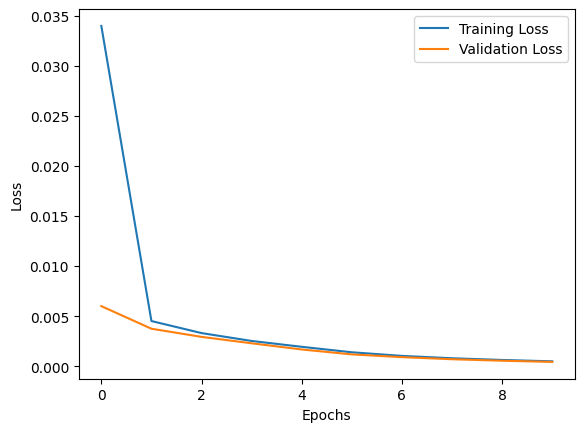

In [21]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [22]:
train_pred = model.predict(x_train)

train_error = np.mean(np.square(x_train - train_pred), axis=(1, 2))

threshold = np.mean(train_error) + 3 * np.std(train_error)

print("Threshold:", threshold)

439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 574us/step
Threshold: 0.0014808153408317106


In [23]:
test_pred = model.predict(x_test)

test_error = np.mean(np.square(x_test - test_pred), axis=(1, 2))

y_pred = (test_error > threshold).astype(int)

print("Detected Faults:", np.sum(y_pred))

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 403us/step
Detected Faults: 142


In [24]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[3440   67]
 [ 545   75]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.98      0.92      3507
           1       0.53      0.12      0.20       620

    accuracy                           0.85      4127
   macro avg       0.70      0.55      0.56      4127
weighted avg       0.81      0.85      0.81      4127

